In [22]:
import os
import re
import glob
import time
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator
# %matplotlib tk
from JunoPy.index import IndexFile
from JunoPy.mag import MagData
from JunoPy.waves import WavesData, WavesDataDas
from JunoPy.jedi import JediData
from JunoPy.library import find_ticks_between

In [35]:
# startevent = dt.datetime.strptime('2018-085T11:35:20', '%Y-%jT%H:%M:%S')
# endevent   = dt.datetime.strptime('2018-085T11:35:44', '%Y-%jT%H:%M:%S')
# startevent = dt.datetime.strptime('2017-236T20:21:15', '%Y-%jT%H:%M:%S')
# endevent   = dt.datetime.strptime('2017-236T20:21:38', '%Y-%jT%H:%M:%S')
startevent = dt.datetime.strptime('2017-338T01:49:57', '%Y-%jT%H:%M:%S')
endevent   = dt.datetime.strptime('2017-338T01:51:00', '%Y-%jT%H:%M:%S')
# startevent = dt.datetime.strptime('2017-338T10:38:57', '%Y-%jT%H:%M:%S')
# endevent   = dt.datetime.strptime('2017-338T11:08:00', '%Y-%jT%H:%M:%S')
start = startevent - dt.timedelta(minutes=100)
end   = endevent + dt.timedelta(minutes=120)

In [36]:
magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
magdata = MagData(filename=magfile)

try:
    wavesfile = glob.glob('data/waves-survey/*{:s}*_E_V01.CSV'.format(start.strftime('%Y%j')))[0]
    wavesdata = WavesData(filename=wavesfile)
    
except IndexError:
    wavesindex = IndexFile(dataset='waves-survey')
    wavesindex.get_files_between_dates(
        start, end, DoDownload=True)
    wavesfile = glob.glob('data/waves-survey/*{:s}*_E_V01.CSV'.format(start.strftime('%Y%j')))[0]
    wavesdata = WavesData(filename=wavesfile)
# wavesdata = WavesDataDas(start, end)

jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
if not jedifiles:
    jediindex = IndexFile(dataset='jedi')
    jediindex.get_files_between_dates(
        start, end, DoDownload=True, sid='ERSESP')
    
jedidata = []
for jedifile in jedifiles:
    jedidata.append(JediData(filename=jedifile))
    print(jedifile)

data/jedi/JED_180_LOERSESP_CDR_2017338_V03.TAB
data/jedi/JED_270_LOERSESP_CDR_2017338_V03.TAB


/opt/anaconda3/envs/JunoPy/lib/python3.8/site-packages/matplotlib-3.2.1-py3.8-macosx-10.9-x86_64.egg/matplotlib/colors.py:1171: RuntimeWarning: invalid value encountered in less_equal
  mask |= resdat <= 0


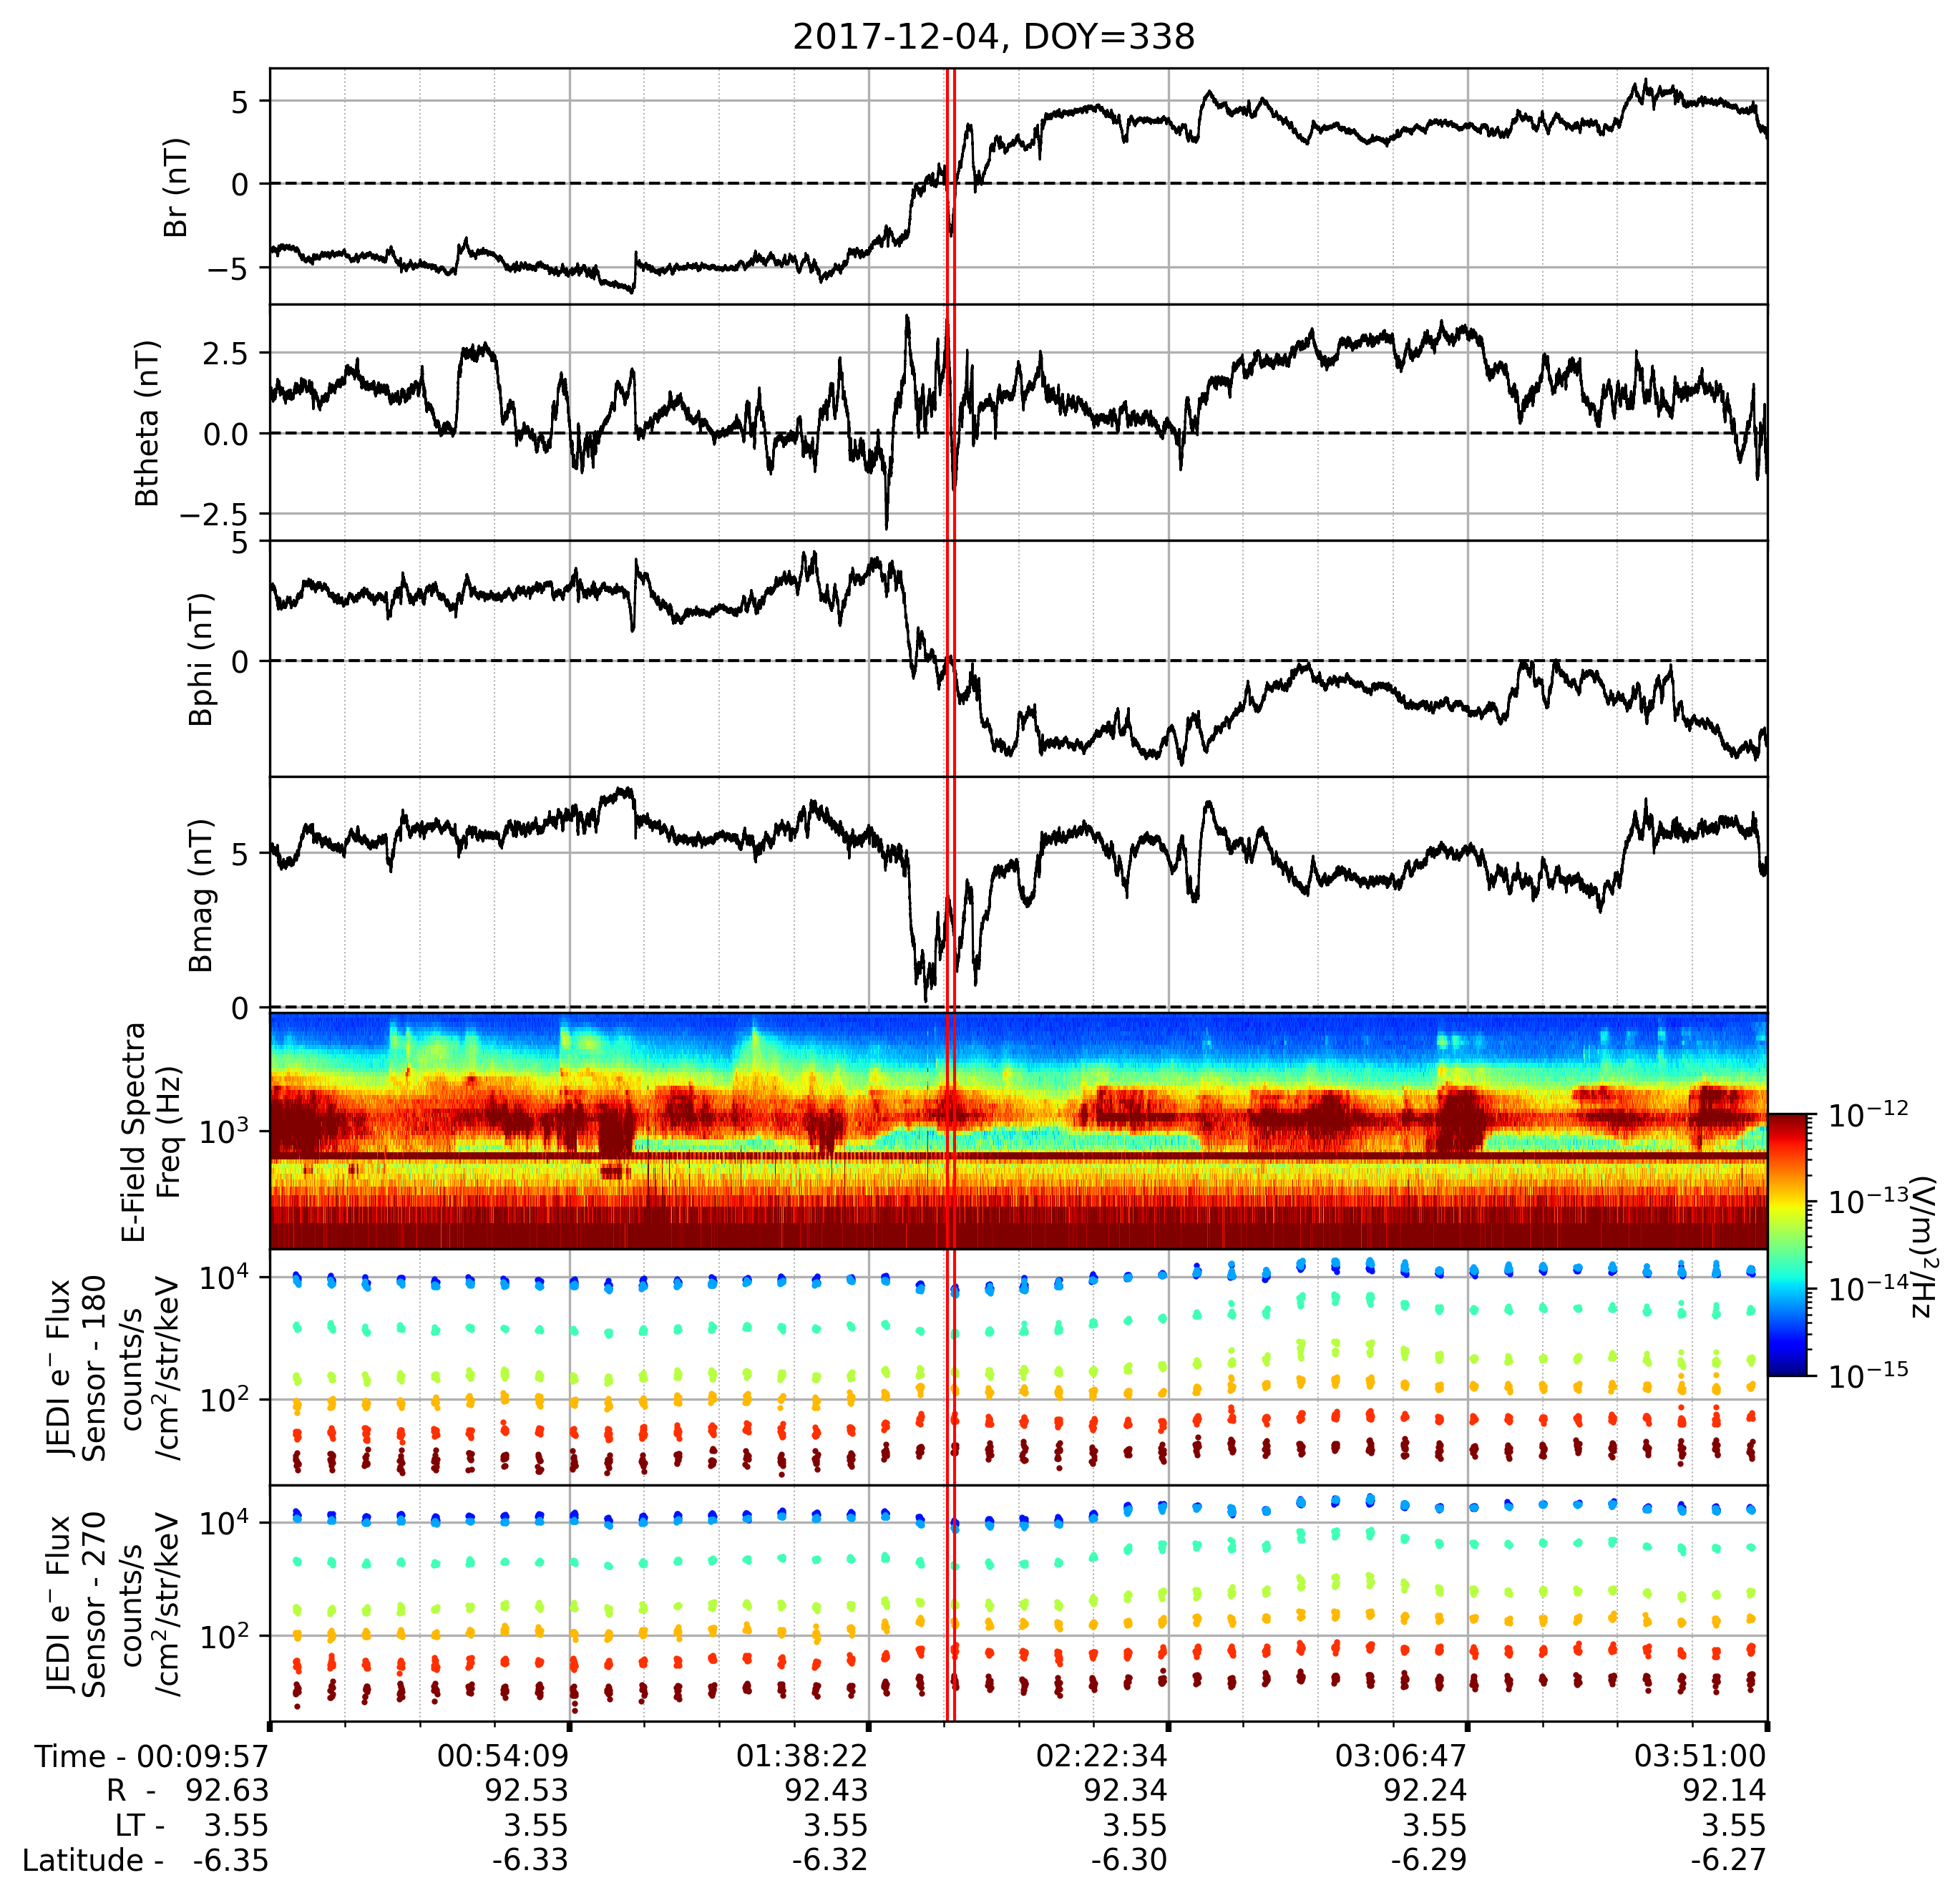

In [37]:
def plot_data(magdata, wavesdata, jedidata, start, end, startevent=None, endevent=None, outfolder=None):
    """Plot data between start and end."""
    
    # Slice the data.
    magdata.df = magdata.df.loc[start:end]
    wavesdata.df = wavesdata.df.loc[start:end]
    for jdata in jedidata:
        jdata.df = jdata.df.loc[start:end]
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(5 + len(jedidata), 1, 
                            gridspec_kw={'hspace': 0, 'right':0.9, 'top':0.9}, 
                            figsize=(9, 11), 
                            dpi=300)
    
    axs[:4] = magdata.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs[:4])
    axs[4] = wavesdata.plot(axs[4], freqlimit=True, vmin=1e-15, vmax=1e-12, )
    
    for i, jdata in enumerate(jedidata):
        if 'LO' in jdata.filename:
            axs[5 + i] = jdata.plot_low_res_line_plots(
                axs[5 + i], iTele=0)
        else:
            axs[5 + i] = jdata.plot_flux_spectra(
                axs[5 + i], iTele=0)
        
        
    
    for a in axs:
        # a.set_xlim([timearray[0], timearray[-1]])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.label_outer()
        a.axvline(startevent, color='red', lw=1.)
        a.axvline(endevent, color='red', lw=1.)
            
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.92)
    
    if outfolder:
        fig.savefig(outfolder + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
        plt.close(fig)
    
    # fig.savefig('out_mva_temp/' + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
    
    # plt.close(fig)
    
plot_data(magdata, wavesdata, jedidata, start, end, startevent=startevent, endevent=endevent)

## 2. Read the CSV file and obtain all times.

In [ ]:
def read_csv_file():
    start_times = []
    end_times = []
    durations = []
    with open('mva_epochs.csv', 'r') as f:
        f.readline()
        for line in f:
            start_times.append(dt.datetime.strptime(line.split(',')[0], '%Y-%jT%H:%M:%S'))
            end_times.append(dt.datetime.strptime(line.split(',')[1], '%Y-%jT%H:%M:%S'))
            durations.append(float(line.split(',')[2]))
    return start_times, end_times, durations
        
start_times, end_times, durations = read_csv_file()

In [ ]:
outfolder = 'out_mag_waves_jedi/'
if not os.path.exists(outfolder):
    os.mkdir(outfolder)
    
for s, e in zip(start_times, end_times):
    
    start = s - dt.timedelta(minutes=10)
    end   = e + dt.timedelta(minutes=10)

    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata = MagData(filename=magfile)
    wavesfile = glob.glob('data/waves-survey/*{:s}*_E_V01.CSV'.format(start.strftime('%Y%j')))[0]
    wavesdata = WavesData(filename=wavesfile)

    try:
        jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
        jedidata = []
        if not jedifiles:
            jediindex = IndexFile(dataset='jedi')
            jediindex.get_files_between_dates(
                start, end, DoDownload=True, sid='ERSESP')
            jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))

        for jedifile in jedifiles:
            jedidata.append(JediData(filename=jedifile))

        try:
            plot_data(magdata, wavesdata, jedidata, start, end, startevent=s, endevent=e, outfolder=outfolder)
        except KeyError:
            continue
    except:
        continue
        